# 01 · Exploratory data analysis

Food-101 images (after `data/prepare_food101.py`) and the USDA-derived nutrition table (`data/nutrition.csv`).

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath('..'))
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from PIL import Image
ROOT = os.path.abspath('..')
IMG_ROOT = f'{ROOT}/data/cache/food101_256'
idx = pd.read_csv(f'{IMG_ROOT}/index.csv')
os.makedirs(f'{ROOT}/assets', exist_ok=True)
idx.groupby('split').size()

split
test     25250
train    75750
dtype: int64

## Class balance
Food-101 is perfectly balanced: 750 train and 250 test images per class. Balanced classes mean plain top-1 accuracy is a fair headline metric; macro-F1 is reported as well.

In [2]:
counts = idx.groupby(['label','split']).size().unstack()
print(counts.describe().loc[['min','max','mean']])

split   test  train
min    250.0  750.0
max    250.0  750.0
mean   250.0  750.0


## Image geometry
Images were stored with the short side resized to 256 px (originals have a max side of 512 px). The aspect ratio distribution shows most photos are 4:3 or square, so a center crop keeps most of the dish.

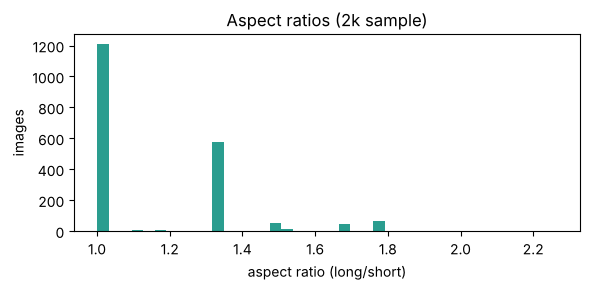

count    2000.00
mean        1.16
std         0.22
min         1.00
25%         1.00
50%         1.00
75%         1.33
max         2.27
dtype: float64


In [3]:
rng = np.random.default_rng(0)
sample = idx.sample(2000, random_state=0)
ar = [ (lambda s: max(s)/min(s))(Image.open(f'{IMG_ROOT}/{p}').size) for p in sample.path]
plt.figure(figsize=(6,3)); plt.hist(ar, bins=40, color='#2a9d8f'); plt.xlabel('aspect ratio (long/short)'); plt.ylabel('images'); plt.title('Aspect ratios (2k sample)'); plt.tight_layout(); plt.show()
print(pd.Series(ar).describe().round(2))

## Sample images
A random image from 16 classes. Food-101 training images were deliberately **not cleaned** by the dataset authors and contain some label noise (wrong labels, intense colours), which caps the achievable accuracy.

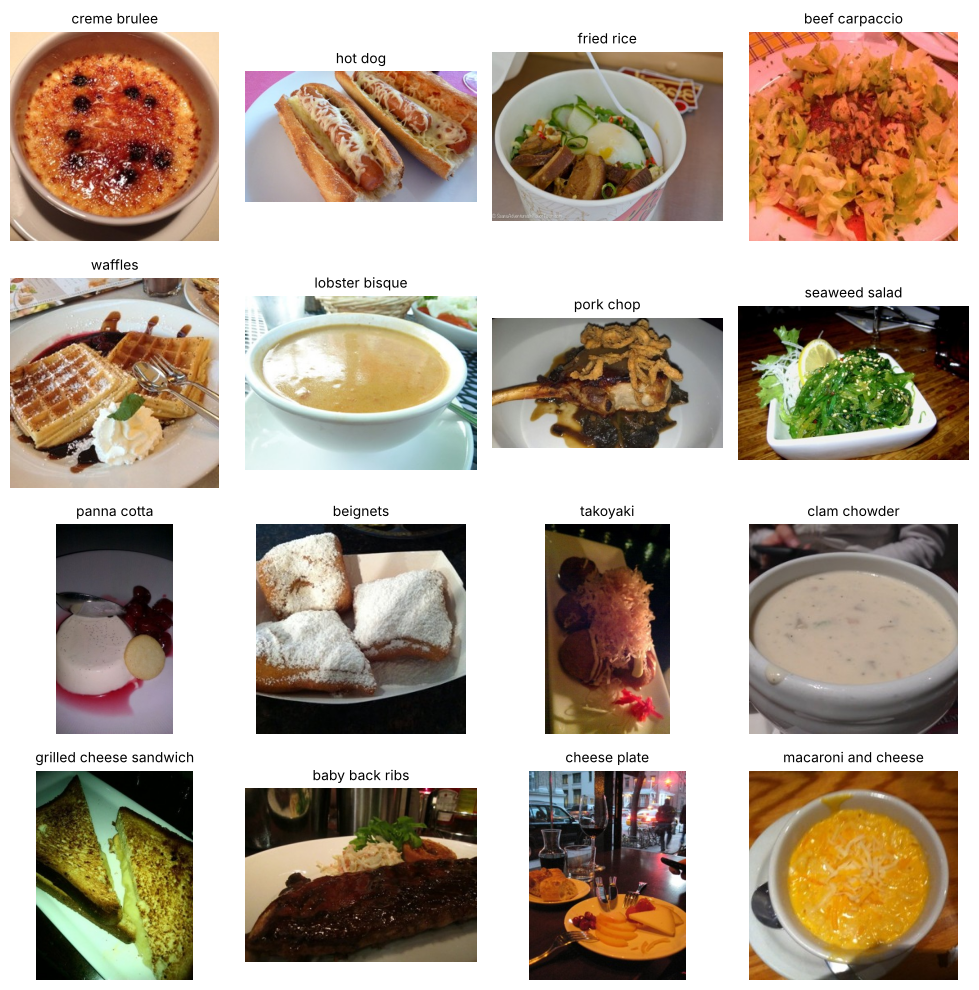

In [4]:
classes = sorted(idx.label.unique())
pick = rng.choice(classes, 16, replace=False)
fig, axes = plt.subplots(4, 4, figsize=(10, 10))
for ax, c in zip(axes.flat, pick):
    p = idx[(idx.label == c) & (idx.split == 'train')].sample(1, random_state=1).path.iloc[0]
    ax.imshow(Image.open(f'{IMG_ROOT}/{p}')); ax.set_title(c.replace('_',' '), fontsize=10); ax.axis('off')
plt.tight_layout(); plt.savefig(f'{ROOT}/assets/sample_grid.jpg', dpi=80); plt.show()

## Nutrition table

In [5]:
nut = pd.read_csv(f'{ROOT}/data/nutrition.csv')
nut['kcal_per_serving'] = nut.kcal_per_100g * nut.serving_g / 100
print(nut.match.value_counts().to_string())
nut[['kcal_per_100g','protein_per_100g','carbs_per_100g','fat_per_100g','serving_g','kcal_per_serving']].describe().round(1)

match
exact        67
composite    18
close        14
proxy         2


,kcal_per_100g,protein_per_100g,carbs_per_100g,fat_per_100g,serving_g,kcal_per_serving
count,101.0,101.0,101.0,101.0,101.0,101.0
mean,221.9,9.2,19.0,12.1,163.4,335.3
std,102.7,6.4,15.4,7.1,74.6,177.8
min,24.0,2.0,0.0,0.7,60.0,43.4
25%,143.0,4.2,6.5,6.3,102.0,198.9
50%,214.0,7.4,16.2,11.8,150.0,304.0
75%,287.0,12.6,28.1,16.3,200.0,429.0
max,514.0,30.5,61.2,41.2,400.0,883.6


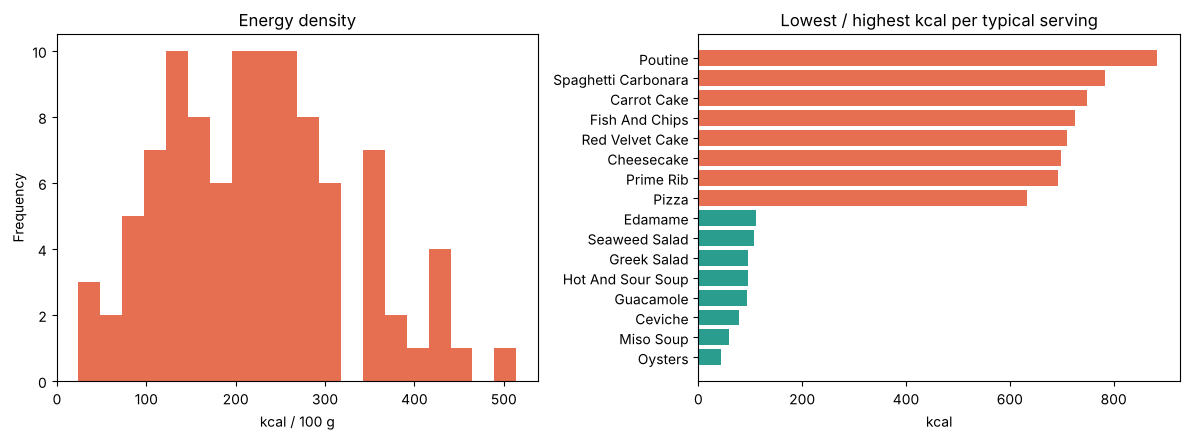

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
nut.kcal_per_100g.plot.hist(bins=20, ax=ax[0], color='#e76f51'); ax[0].set(title='Energy density', xlabel='kcal / 100 g')
s = nut.sort_values('kcal_per_serving')
show = pd.concat([s.head(8), s.tail(8)])
ax[1].barh(show.display_name, show.kcal_per_serving, color=['#2a9d8f']*8 + ['#e76f51']*8)
ax[1].set(title='Lowest / highest kcal per typical serving', xlabel='kcal')
plt.tight_layout(); plt.savefig(f'{ROOT}/assets/nutrition_overview.png', dpi=100); plt.show()

Macro composition: share of energy from protein / carbs / fat. Desserts cluster at high-carb, meats at high-protein-and-fat, which is why a misclassification between *visually similar but nutritionally different* dishes (e.g. steak ↔ filet mignon is harmless; risotto ↔ fried rice is not) matters more than the raw error rate.

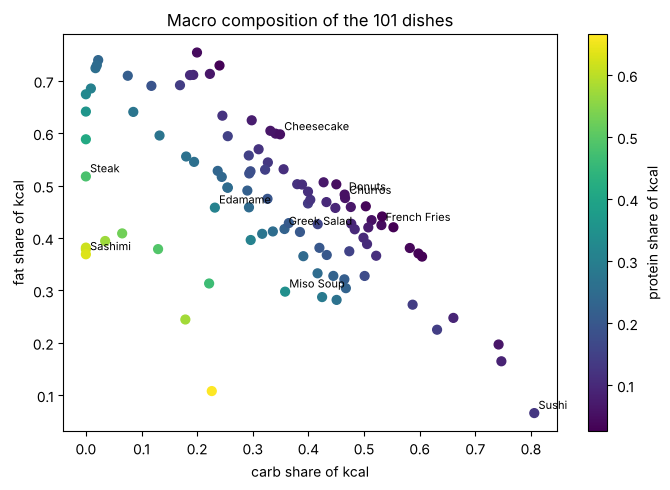

In [7]:
e = nut.assign(P=4*nut.protein_per_100g, Cb=4*nut.carbs_per_100g, F=9*nut.fat_per_100g)
tot = e.P + e.Cb + e.F
plt.figure(figsize=(7,5))
sc = plt.scatter(e.Cb/tot, e.F/tot, c=e.P/tot, cmap='viridis', s=40)
for _, r in e.iterrows():
    if r['class'] in ['steak','sushi','cheesecake','french_fries','edamame','miso_soup','greek_salad','churros','sashimi','donuts']:
        plt.annotate(r.display_name, ((r.Cb/(r.P+r.Cb+r.F)), r.F/(r.P+r.Cb+r.F)), fontsize=8, xytext=(3,3), textcoords='offset points')
plt.colorbar(sc, label='protein share of kcal'); plt.xlabel('carb share of kcal'); plt.ylabel('fat share of kcal'); plt.title('Macro composition of the 101 dishes')
plt.tight_layout(); plt.show()